In [13]:
import numpy as np
import matplotlib.pyplot as plt

# IEEE-friendly publication styling
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
})

CONDITIONS = ["Reference", "Cap.-lim.", "Obs.-lim.", "Comm.-lim.", "Combined"]
x = np.arange(len(CONDITIONS))

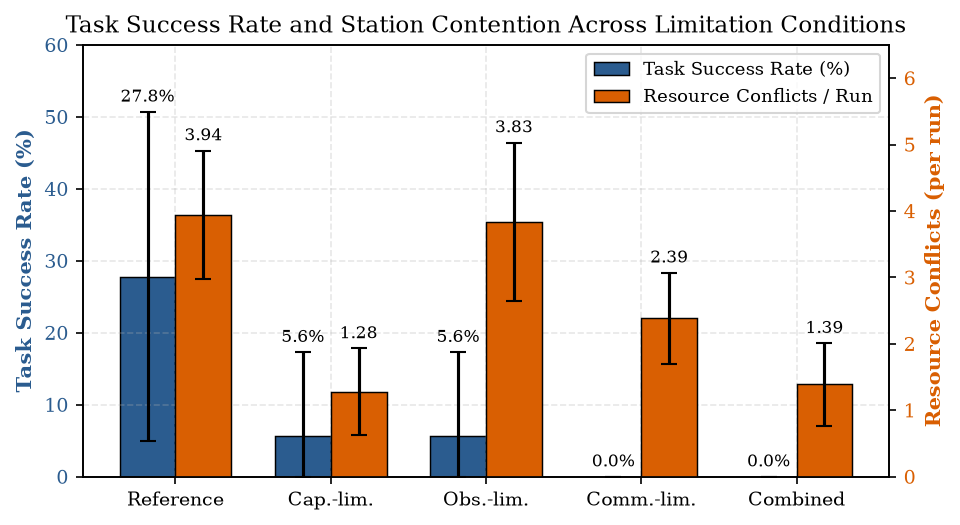

In [14]:
# Data from Table III & Table V (n = 18 runs per condition)
success_mean = np.array([27.8, 5.6, 5.6, 0.0, 0.0])
# Asymmetric/clipped 95% CI error bars for Success Rate [0, 100]
success_ci_low  = np.array([27.8 - 4.9, 5.6 - 0.0, 5.6 - 0.0, 0.0, 0.0])
success_ci_high = np.array([50.7 - 27.8, 17.3 - 5.6, 17.3 - 5.6, 0.0, 0.0])

# Resource Conflicts (per run) from Table V: Mean and 95% CI
conflicts_mean    = np.array([3.94, 1.28, 3.83, 2.39, 1.39])
conflicts_ci_low  = np.array([3.94 - 2.98, 1.28 - 0.62, 3.83 - 2.64, 2.39 - 1.70, 1.39 - 0.77])
conflicts_ci_high = np.array([4.91 - 3.94, 1.93 - 1.28, 5.03 - 3.83, 3.07 - 2.39, 2.01 - 1.39])

fig, ax1 = plt.subplots(figsize=(6.5, 3.6))
width = 0.36

# Bar 1: Task Success Rate (Left Y-Axis)
rects1 = ax1.bar(
    x - width / 2, success_mean, width,
    yerr=[success_ci_low, success_ci_high], capsize=4,
    label="Task Success Rate (%)", color="#2b5c8f", edgecolor="black", linewidth=0.7
)
ax1.set_ylabel("Task Success Rate (%)", color="#2b5c8f", fontweight="bold")
ax1.tick_params(axis="y", labelcolor="#2b5c8f")
ax1.set_ylim(0, 60)

# Bar 2: Resource Conflicts (Right Y-Axis)
ax2 = ax1.twinx()
ax2.grid(False)
rects2 = ax2.bar(
    x + width / 2, conflicts_mean, width,
    yerr=[conflicts_ci_low, conflicts_ci_high], capsize=4,
    label="Resource Conflicts / Run", color="#d95f02", edgecolor="black", linewidth=0.7
)
ax2.set_ylabel("Resource Conflicts (per run)", color="#d95f02", fontweight="bold")
ax2.tick_params(axis="y", labelcolor="#d95f02")
ax2.set_ylim(0, 6.5)

ax1.set_xticks(x)
ax1.set_xticklabels(CONDITIONS)
ax1.set_title("Task Success Rate and Station Contention Across Limitation Conditions")

# Value annotations above bars (placed above upper CI error bar)
for i, r in enumerate(rects1):
    h = r.get_height()
    top = h + success_ci_high[i]
    ax1.annotate(f"{h:.1f}%", xy=(r.get_x() + r.get_width() / 2, top),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)

for i, r in enumerate(rects2):
    h = r.get_height()
    top = h + conflicts_ci_high[i]
    ax2.annotate(f"{h:.2f}", xy=(r.get_x() + r.get_width() / 2, top),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig("fig1_success_vs_conflicts.pdf")
plt.savefig("fig1_success_vs_conflicts.png")
plt.show()

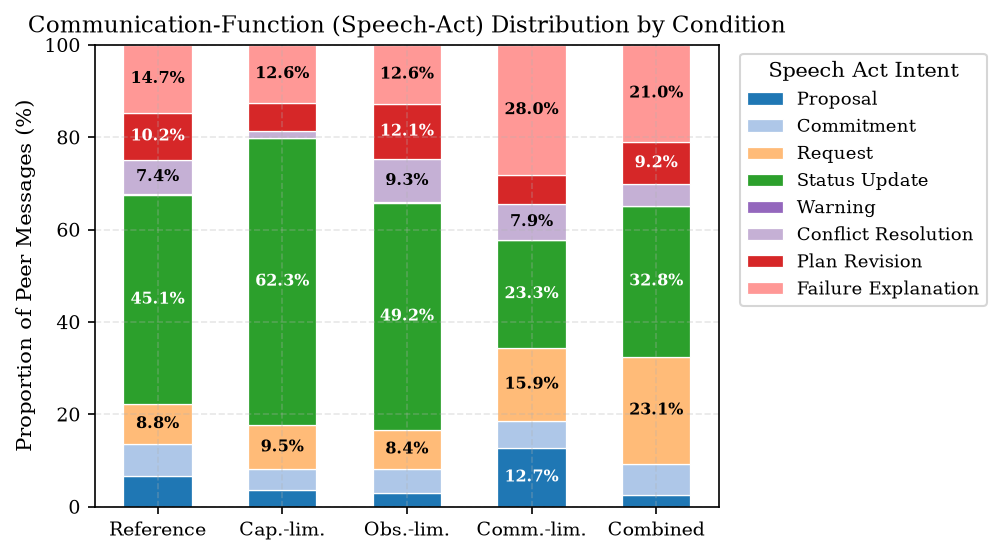

In [15]:
# Data from Table VIII (Percentage share of each communication intent per condition)
speech_acts = {
    "Proposal":             np.array([6.6,  3.6,  3.0,  12.7, 2.6]),
    "Commitment":           np.array([6.9,  4.5,  5.2,  5.8,  6.7]),
    "Request":              np.array([8.8,  9.5,  8.4,  15.9, 23.1]),
    "Status Update":        np.array([45.1, 62.3, 49.2, 23.3, 32.8]),
    "Warning":              np.array([0.3,  0.0,  0.1,  0.0,  0.0]),
    "Conflict Resolution":  np.array([7.4,  1.4,  9.3,  7.9,  4.6]),
    "Plan Revision":        np.array([10.2, 6.1,  12.1, 6.3,  9.2]),
    "Failure Explanation":  np.array([14.7, 12.6, 12.6, 28.0, 21.0]),
}

colors = [
    "#1f77b4", "#aec7e8", "#ffbb78", "#2ca02c",
    "#9467bd", "#c5b0d5", "#d62728", "#ff9896"
]

fig, ax = plt.subplots(figsize=(6.8, 3.8))
bottom = np.zeros(len(CONDITIONS))

for (label, values), color in zip(speech_acts.items(), colors):
    bars = ax.bar(
        CONDITIONS, values, width=0.55, bottom=bottom,
        label=label, color=color, edgecolor="white", linewidth=0.6
    )
    # Add percentage labels inside segments >= 7%
    for i, val in enumerate(values):
        if val >= 7.0:
            ax.text(
                i, bottom[i] + val / 2, f"{val:.1f}%",
                ha="center", va="center", fontsize=7.5,
                color="white" if color in ("#1f77b4", "#2ca02c", "#9467bd", "#d62728") else "black",
                fontweight="bold"
            )
    bottom += values

ax.set_ylabel("Proportion of Peer Messages (%)")
ax.set_ylim(0, 100)
ax.set_title("Communication-Function (Speech-Act) Distribution by Condition")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, title="Speech Act Intent")

plt.tight_layout()
plt.savefig("fig2_speech_act_distribution.pdf")
plt.savefig("fig2_speech_act_distribution.png")
plt.show()

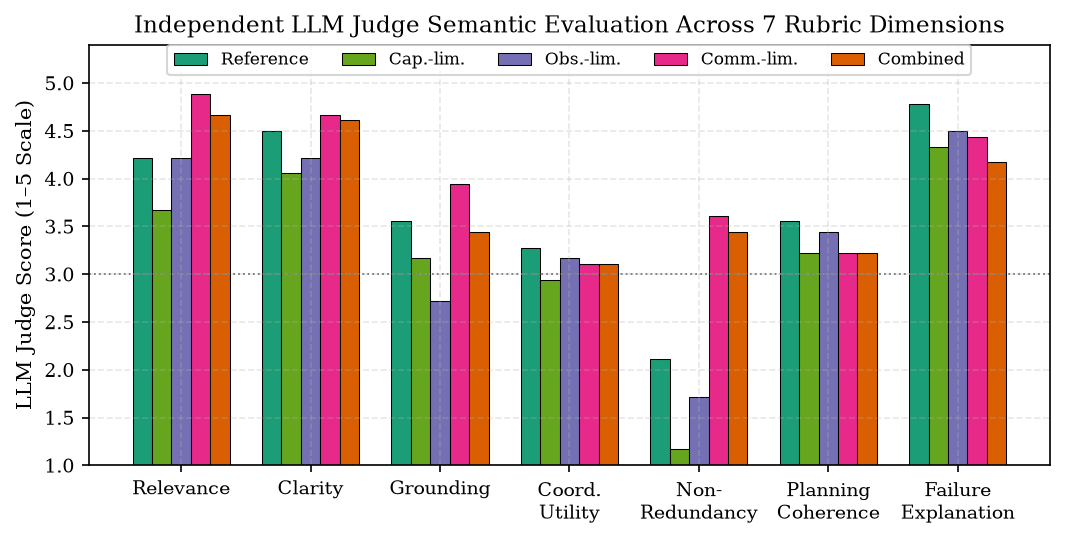

In [16]:
# Data from Table IX (1-5 Likert ratings across the 7 semantic rubric dimensions)
dimensions = [
    "Relevance",
    "Clarity",
    "Grounding",
    "Coord.\nUtility",
    "Non-\nRedundancy",
    "Planning\nCoherence",
    "Failure\nExplanation",
]

judge_scores = {
    "Reference":   [4.22, 4.50, 3.56, 3.28, 2.11, 3.56, 4.78],
    "Cap.-lim.":   [3.67, 4.06, 3.17, 2.94, 1.17, 3.22, 4.33],
    "Obs.-lim.":   [4.22, 4.22, 2.72, 3.17, 1.72, 3.44, 4.50],
    "Comm.-lim.":  [4.89, 4.67, 3.94, 3.11, 3.61, 3.22, 4.44],
    "Combined":    [4.67, 4.61, 3.44, 3.11, 3.44, 3.22, 4.17],
}

cond_colors = ["#1b9e77", "#66a61e", "#7570b3", "#e7298a", "#d95f02"]
x_dim = np.arange(len(dimensions))
bar_w = 0.15

fig, ax = plt.subplots(figsize=(7.2, 3.7))

for idx, (cond, scores) in enumerate(judge_scores.items()):
    offset = (idx - 2) * bar_w
    ax.bar(
        x_dim + offset, scores, width=bar_w,
        label=cond, color=cond_colors[idx], edgecolor="black", linewidth=0.5
    )

ax.set_ylabel("LLM Judge Score (1–5 Scale)")
ax.set_ylim(1.0, 5.4)
ax.set_xticks(x_dim)
ax.set_xticklabels(dimensions)
ax.set_title("Independent LLM Judge Semantic Evaluation Across 7 Rubric Dimensions")
ax.axhline(3.0, color="gray", linestyle=":", linewidth=0.9)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.02), frameon=True, fontsize=8)

plt.tight_layout()
plt.savefig("fig3_llm_judge_dimensions.pdf")
plt.savefig("fig3_llm_judge_dimensions.png")
plt.show()

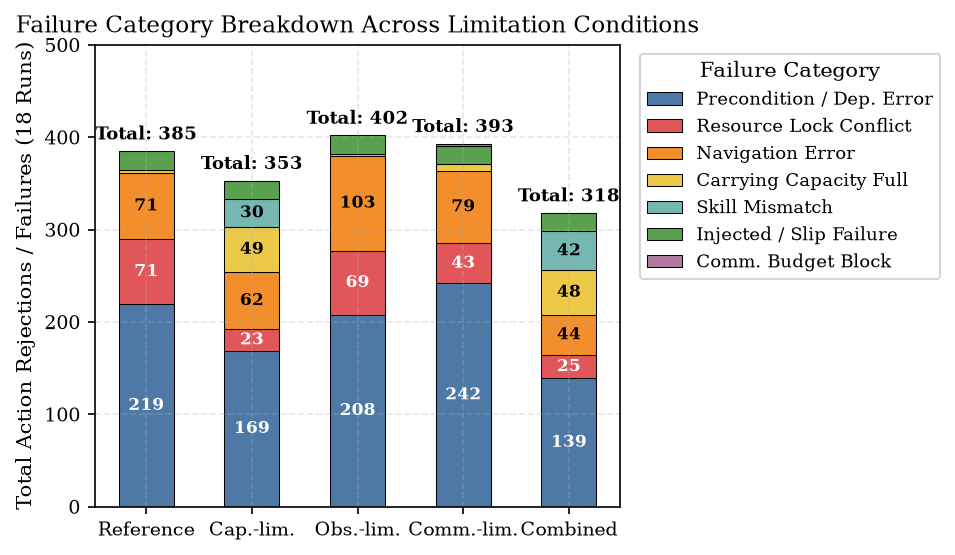

In [ ]:
# Data from Table XI (Total failure counts across n = 18 runs per condition)
failure_categories = {
    "Precondition / Dep. Error": [219, 169, 208, 242, 139],
    "Resource Lock Conflict":    [71,  23,  69,  43,  25],
    "Navigation Error":          [71,  62,  103, 79,  44],
    "Carrying Capacity Full":    [4,   49,  2,   7,   48],
    "Skill Mismatch":            [0,   30,  0,   0,   42],
    "Injected / Slip Failure":   [20,  20,  20,  20,  20],
    "Comm. Budget Block":        [0,   0,   0,   2,   0],
}
fail_colors = ["#4e79a7", "#e15759", "#f28e2b", "#edc948", "#76b7b2", "#59a14f", "#b07aa1"]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
bottom = np.zeros(len(CONDITIONS))
for (cat_label, counts), color in zip(failure_categories.items(), fail_colors):
    counts_arr = np.array(counts)
    ax.bar(
        CONDITIONS, counts_arr, width=0.52, bottom=bottom,
        label=cat_label, color=color, edgecolor="black", linewidth=0.5
    )
    for i, val in enumerate(counts_arr):
        if val >= 23:
            ax.text(
                i, bottom[i] + val / 2, str(val),
                ha="center", va="center", fontsize=8, fontweight="bold",
                color="white" if color in ("#4e79a7", "#e15759", "#59a14f") else "black"
            )
    bottom += counts_arr
# Annotate total failures on top of each bar
for i, total in enumerate(bottom):
    ax.text(i, total + 8, f"Total: {int(total)}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
ax.set_ylabel("Total Action Rejections / Failures (18 Runs)")
ax.set_ylim(0, 500)
ax.set_title("Failure Category Breakdown Across Limitation Conditions")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, title="Failure Category")
plt.tight_layout()
plt.show()